# Análise de Dados E-Commerce (Olist)

## Pergunta norteadora
> **O que explica os atrasos nas entregas e como eles afetam a satisfação do cliente?**

Perguntas de apoio:
1. Qual é o tempo típico de entrega e quantos pedidos atrasam?
2. O atraso varia entre estados?
3. Atrasar reduz a nota de avaliação do cliente?
4. Como o volume de pedidos evoluiu e quais estados e categorias concentram as vendas?

## Estrutura (conforme as fases do projeto)
| Fase | Onde está |
|---|---|
| 1. Seleção dos dados | Seção 1 (Olist: 6 tabelas, 1 base pública do Kaggle) |
| 3. Tratamento e preparação | Seções 3 a 6 |
| 2. Análise exploratória | Seção 7 (10 análises) |
| 4. Visualização | Seção 7 + Seção 8 (exportação para o Google Data Studio) |

**Fonte:** [Brazilian E-Commerce Public Dataset by Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)

## 1. Seleção dos dados

### 1.1 Setup

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

### 1.2 Carregar os dados

In [ ]:
ARQUIVOS = [
    'olist_orders_dataset.csv',
    'olist_order_items_dataset.csv',
    'olist_customers_dataset.csv',
    'olist_products_dataset.csv',
    'olist_order_reviews_dataset.csv',
    'product_category_name_translation.csv',
]

try:
    from google.colab import files
    faltando = [a for a in ARQUIVOS if not os.path.exists(a)]
    if faltando:
        print("Selecione estes arquivos:", faltando)
        files.upload()
except ImportError:
    print("Fora do Colab: os CSVs precisam estar na pasta do notebook.")

In [ ]:
df_orders    = pd.read_csv('olist_orders_dataset.csv')
df_items     = pd.read_csv('olist_order_items_dataset.csv')
df_customers = pd.read_csv('olist_customers_dataset.csv')
df_products  = pd.read_csv('olist_products_dataset.csv')
df_trans     = pd.read_csv('product_category_name_translation.csv')
df_reviews   = pd.read_csv('olist_order_reviews_dataset.csv',
                           usecols=['order_id', 'review_score', 'review_answer_timestamp'],
                           parse_dates=['review_answer_timestamp'])

for nome, d in [('orders', df_orders), ('items', df_items), ('customers', df_customers),
                ('products', df_products), ('reviews', df_reviews), ('translation', df_trans)]:
    print(f"{nome:12s} {d.shape[0]:>8,} linhas x {d.shape[1]} colunas")

orders         99,441 linhas x 8 colunas
items         112,650 linhas x 7 colunas
customers      99,441 linhas x 5 colunas
products       32,951 linhas x 9 colunas
reviews        99,224 linhas x 3 colunas
translation        71 linhas x 2 colunas


## 2. Primeira olhada nos dados (nulos e duplicatas)

In [ ]:
print("order_id duplicado em orders:      ", df_orders['order_id'].duplicated().sum())
print("customer_id duplicado em customers:", df_customers['customer_id'].duplicated().sum())
print("product_id duplicado em products:  ", df_products['product_id'].duplicated().sum())
print("order_id duplicado em reviews:     ", df_reviews['order_id'].duplicated().sum(), "<- pedidos com mais de 1 avaliação")

nulos = pd.DataFrame({
    'orders':   df_orders.isna().sum(),
}).query('orders > 0')
print("\nNulos em orders:");   print(nulos)
print("\nNulos em products:"); print(df_products.isna().sum()[lambda s: s > 0])

order_id duplicado em orders:       0
customer_id duplicado em customers: 0
product_id duplicado em products:   0
order_id duplicado em reviews:      551 <- pedidos com mais de 1 avaliação

Nulos em orders:
                               orders
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

Nulos em products:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


## 3. Padronização de tipos

In [ ]:
# Datas: string -> datetime
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
]
for col in date_columns:
    df_orders[col] = pd.to_datetime(df_orders[col])
df_items['shipping_limit_date'] = pd.to_datetime(df_items['shipping_limit_date'])

# Colunas com poucos valores repetidos: category economiza memória
df_customers['customer_state'] = df_customers['customer_state'].astype('category')
df_orders['order_status'] = df_orders['order_status'].astype('category')

## 4. Checagem de inconsistências

In [ ]:
entregue = df_orders['order_status'] == 'delivered'
checagens = {
    'Pedido "delivered" sem data de entrega':            (entregue & df_orders['order_delivered_customer_date'].isna()).sum(),
    'Pedido NÃO entregue com data de entrega':           (~entregue & df_orders['order_delivered_customer_date'].notna()).sum(),
    'Entrega antes da compra':                           (df_orders['order_delivered_customer_date'] < df_orders['order_purchase_timestamp']).sum(),
    'Aprovação antes da compra':                         (df_orders['order_approved_at'] < df_orders['order_purchase_timestamp']).sum(),
    'Entrega ao cliente antes da saída da transportadora': (df_orders['order_delivered_customer_date'] < df_orders['order_delivered_carrier_date']).sum(),
    'Itens com preço <= 0':                              (df_items['price'] <= 0).sum(),
    'Itens com frete < 0':                               (df_items['freight_value'] < 0).sum(),
    'Produtos com peso = 0':                             (df_products['product_weight_g'] == 0).sum(),
    'Avaliações com nota fora de 1 a 5':                 (~df_reviews['review_score'].between(1, 5)).sum(),
}
display(pd.Series(checagens, name='ocorrências').to_frame())

,ocorrências
"Pedido ""delivered"" sem data de entrega",8
Pedido NÃO entregue com data de entrega,6
Entrega antes da compra,0
Aprovação antes da compra,0
Entrega ao cliente antes da saída da transportadora,23
Itens com preço <= 0,0
Itens com frete < 0,0
Produtos com peso = 0,4
Avaliações com nota fora de 1 a 5,0


## 5. Tratamento dos dados

In [ ]:
# Peso zero -> nulo
df_products.loc[df_products['product_weight_g'] == 0, 'product_weight_g'] = np.nan

# Tradução das categorias (PT -> EN)
df_products = df_products.merge(df_trans, on='product_category_name', how='left', validate='many_to_one')
df_products['product_category_name_english'] = (
    df_products['product_category_name_english'].fillna(df_products['product_category_name'])
)

# Uma avaliação por pedido (a mais recente)
df_reviews_unica = (
    df_reviews.sort_values('review_answer_timestamp')
    .drop_duplicates('order_id', keep='last')[['order_id', 'review_score']]
)
print(f"Avaliações: {len(df_reviews):,} -> {len(df_reviews_unica):,} (uma por pedido)")

Avaliações: 99,224 -> 98,673 (uma por pedido)


## 6. Consolidação (JOINs) e colunas derivadas

In [ ]:
df_merged = pd.merge(df_orders, df_items, on='order_id', how='left', validate='one_to_many')
df_merged = pd.merge(df_merged, df_customers, on='customer_id', how='left', validate='many_to_one')
df_merged = pd.merge(df_merged, df_products, on='product_id', how='left', validate='many_to_one')

assert df_merged['order_id'].nunique() == len(df_orders), "Número de pedidos mudou após os joins!"

print(f"Pedidos únicos:          {df_merged['order_id'].nunique():,}")
print(f"Linhas (itens):          {len(df_merged):,}")
print(f"Pedidos sem nenhum item: {df_merged['price'].isna().sum():,}")
print(f"Memória: {df_merged.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

Pedidos únicos:          99,441
Linhas (itens):          113,425
Pedidos sem nenhum item: 775
Memória: 78.6 MB


In [ ]:
# --- Colunas derivadas ---
# 1. Tempo real de entrega em dias
df_merged['tempo_entrega_dias'] = (
    df_merged['order_delivered_customer_date'] - df_merged['order_purchase_timestamp']
).dt.total_seconds() / (24 * 3600)

# 2. Atraso em dias (real - estimada). > 0: atrasou
df_merged['dias_atraso'] = (
    df_merged['order_delivered_customer_date'] - df_merged['order_estimated_delivery_date']
).dt.total_seconds() / (24 * 3600)

# 3. Valor total do item (produto + frete)
df_merged['valor_total_item'] = df_merged['price'] + df_merged['freight_value']

# 4. Mês da compra (primeiro dia do mês)
df_merged['ano_mes'] = df_merged['order_purchase_timestamp'].dt.to_period('M').dt.to_timestamp()

# 5. Código do estado no padrão ISO (necessário para o mapa do Looker Studio)
df_merged['uf_br'] = 'BR-' + df_merged['customer_state'].astype(str)

# 6. Categoria final (separa "pedido sem item" de "produto sem categoria")
df_merged['categoria'] = df_merged['product_category_name_english'].astype('object').fillna('sem_categoria')
df_merged.loc[df_merged['product_id'].isna(), 'categoria'] = 'pedido_sem_item'

print(df_merged[['tempo_entrega_dias', 'dias_atraso', 'valor_total_item']].describe().round(2))

       tempo_entrega_dias  dias_atraso  valor_total_item
count           110196.00    110196.00         112650.00
mean                12.47       -11.33            140.64
std                  9.45        10.16            190.72
min                  0.53      -146.02              6.08
25%                  6.74       -16.32             55.22
50%                 10.18       -12.05             92.32
75%                 15.54        -6.48            157.94
max                209.63       188.98           6929.31


### Tabela com um registro por pedido

In [ ]:
soma = lambda s: s.sum(min_count=1)

agg_itens = df_merged.groupby('order_id').agg(
    valor_produtos=('price', soma),
    frete=('freight_value', soma),
    peso_total_g=('product_weight_g', soma),
    n_itens=('order_item_id', 'count'),
).reset_index()

df_ped = (
    df_merged.drop_duplicates('order_id')
    [['order_id', 'order_status', 'order_purchase_timestamp', 'ano_mes',
      'customer_state', 'uf_br', 'tempo_entrega_dias', 'dias_atraso']]
    .merge(agg_itens, on='order_id', how='left', validate='one_to_one')
    .merge(df_reviews_unica, on='order_id', how='left', validate='one_to_one')
)
df_ped['customer_state'] = df_ped['customer_state'].astype(str)

# 7. Faixa de atraso
df_ped['faixa_atraso'] = pd.cut(
    df_ped['dias_atraso'],
    bins=[-np.inf, 0, 3, 7, np.inf],
    labels=['No prazo', 'Atraso até 3 dias', 'Atraso de 3 a 7 dias', 'Atraso > 7 dias'],
)

# 8. Situação da entrega (texto, para o dashboard)
df_ped['situacao_entrega'] = np.select(
    [df_ped['dias_atraso'].isna(), df_ped['dias_atraso'] > 0],
    ['Sem entrega registrada', 'Atrasado'],
    default='No prazo',
)

# Pedidos entregues e com datas coerentes
df_entregues = df_ped[
    (df_ped['order_status'] == 'delivered')
    & df_ped['tempo_entrega_dias'].notna()
    & (df_ped['tempo_entrega_dias'] >= 0)
].copy()

print(f"Pedidos (total):              {len(df_ped):,}")
print(f"Pedidos entregues analisados: {len(df_entregues):,}")
print(f"% de pedidos atrasados:       {(df_entregues['dias_atraso'] > 0).mean():.1%}")
print(f"Pedidos entregues com nota:   {df_entregues['review_score'].notna().mean():.1%}")

Pedidos (total):              99,441
Pedidos entregues analisados: 96,470
% de pedidos atrasados:       8.1%
Pedidos entregues com nota:   99.3%


## 7. Análise exploratória e visualizações

### Análise 1: Distribuição do tempo de entrega

Mediana: 10.2 dias | Média: 12.6 dias | Máximo: 210 dias
Pedidos acima de 60 dias (fora do gráfico): 0.32%


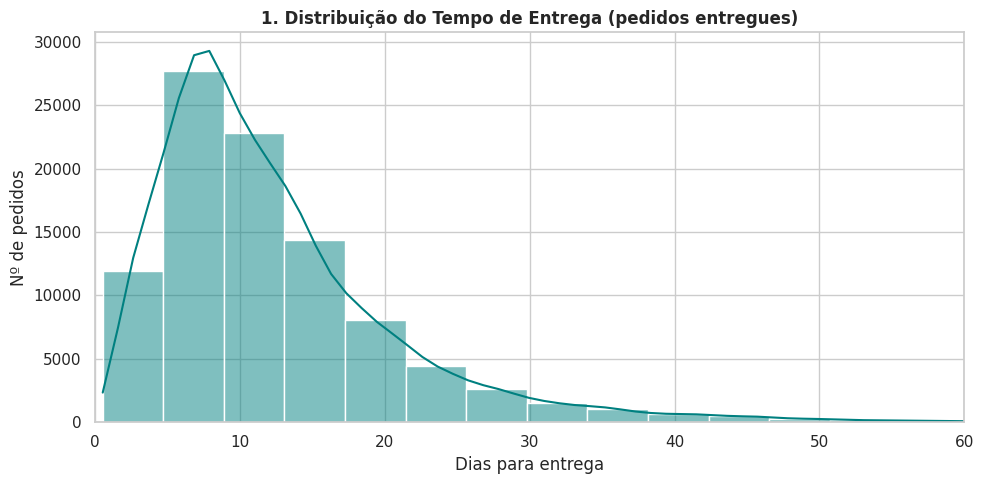

In [ ]:
pct_acima_60 = (df_entregues['tempo_entrega_dias'] > 60).mean()
print(f"Mediana: {df_entregues['tempo_entrega_dias'].median():.1f} dias | Média: {df_entregues['tempo_entrega_dias'].mean():.1f} dias | Máximo: {df_entregues['tempo_entrega_dias'].max():.0f} dias")
print(f"Pedidos acima de 60 dias (fora do gráfico): {pct_acima_60:.2%}")

plt.figure(figsize=(10, 5))
sns.histplot(df_entregues['tempo_entrega_dias'], bins=50, kde=True, color='teal')
plt.title('1. Distribuição do Tempo de Entrega (pedidos entregues)', fontsize=12, fontweight='bold')
plt.xlabel('Dias para entrega')
plt.ylabel('Nº de pedidos')
plt.xlim(0, 60)
plt.tight_layout()
plt.show()

**Minha interpretação:** O tempo típico de entrega (mediana) é de 10,2 dias, ou seja, metade dos pedidos chega em cerca de 10 dias ou menos. A distribuição apresenta assimetria positiva (cauda longa à direita), evidenciada pela média (12,6 dias) ser maior que a mediana. Isso mostra que entregas excepcionalmente longas, que chegam a cerca de 210 dias, puxam a média para cima. Apenas 0,32% dos pedidos levam mais de 60 dias para chegar.

### Análise 2: Outliers no valor total do item

Limite superior (IQR): R$ 312.01
Outliers: 8,253 itens (7.3%) | Maior valor: R$ 6,929.31


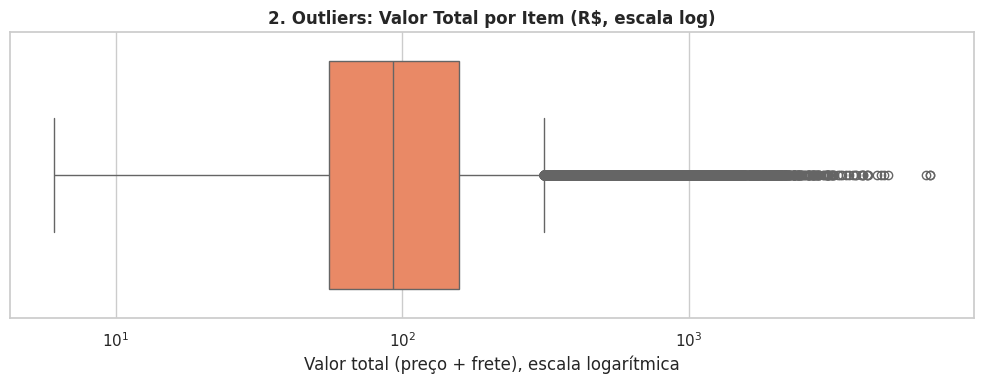

In [ ]:
valores = df_merged['valor_total_item'].dropna()

q1, q3 = valores.quantile([0.25, 0.75])
limite_sup = q3 + 1.5 * (q3 - q1)
n_out = (valores > limite_sup).sum()
print(f"Limite superior (IQR): R$ {limite_sup:.2f}")
print(f"Outliers: {n_out:,} itens ({n_out / len(valores):.1%}) | Maior valor: R$ {valores.max():,.2f}")

plt.figure(figsize=(10, 4))
sns.boxplot(x=valores, color='coral')
plt.xscale('log')
plt.title('2. Outliers: Valor Total por Item (R$, escala log)', fontsize=12, fontweight='bold')
plt.xlabel('Valor total (preço + frete), escala logarítmica')
plt.tight_layout()
plt.show()

**Minha interpretação:** Pelo método da Amplitude Interquartil (IQR), o limite superior para identificação de possíveis valores atípicos é R$ 312,01. Foram identificados 8.253 itens acima desse limite (7,3% da base), e o maior valor total por item foi R$ 6.929,31. Os 50% centrais dos itens apresentam valores entre R$ 55,22 (Q1) e R$ 157,94 (Q3). Esses registros são considerados possíveis outliers estatísticos, mas não necessariamente erros: podem corresponder a produtos de maior valor ou combinações de preço e frete elevadas. A análise não permite determinar, isoladamente, se cada caso é legítimo ou um erro.

### Análise 3: Correlação entre variáveis do pedido

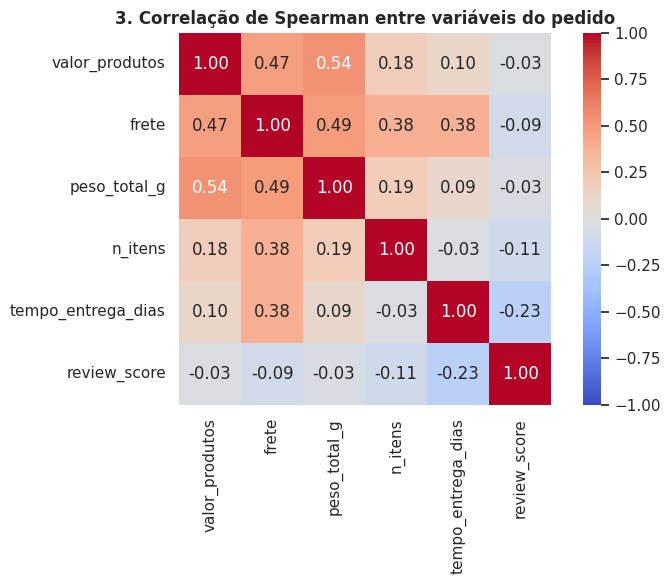

In [ ]:
cols_corr = ['valor_produtos', 'frete', 'peso_total_g', 'n_itens', 'tempo_entrega_dias', 'review_score']
corr_matrix = df_entregues[cols_corr].corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('3. Correlação de Spearman entre variáveis do pedido', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Minha interpretação:** A correlação de Spearman mostra que o valor do frete tem associação moderada com o peso total do pedido ($r_s = 0{,}49$) e com o valor dos produtos ($r_s = 0{,}47$), e associação mais fraca com o tempo de entrega e com o número de itens ($r_s = 0{,}38$ em ambos). Como o frete é a soma dos fretes de todos os itens do pedido, a relação com o número de itens é esperada, e essa matriz sozinha não permite atribuir o frete à distância percorrida. O tempo de entrega apresenta correlação negativa fraca a moderada com a nota de avaliação ($r_s = -0{,}23$): pedidos que demoram mais tendem a receber notas menores. Já o valor dos produtos praticamente não se relaciona com a nota ($r_s = -0{,}03$), o que sugere que a satisfação está mais ligada ao cumprimento dos prazos do que ao ticket do pedido. Vale lembrar que correlação não implica causalidade.

### Análise 4: Média, mediana e dispersão do tempo de entrega por estado

,pedidos,media,mediana,desvio_padrao
customer_state,,,,
SP,40494,8.8,7.2,6.8
MG,11354,12.0,10.3,7.2
PR,4923,12.0,10.4,7.0
DF,2080,13.0,11.4,7.1
RJ,12350,15.3,12.0,11.5
SC,3546,15.0,13.0,8.6
RS,5344,15.3,13.2,9.2
ES,1995,15.8,13.6,10.6
GO,1957,15.6,13.9,9.3


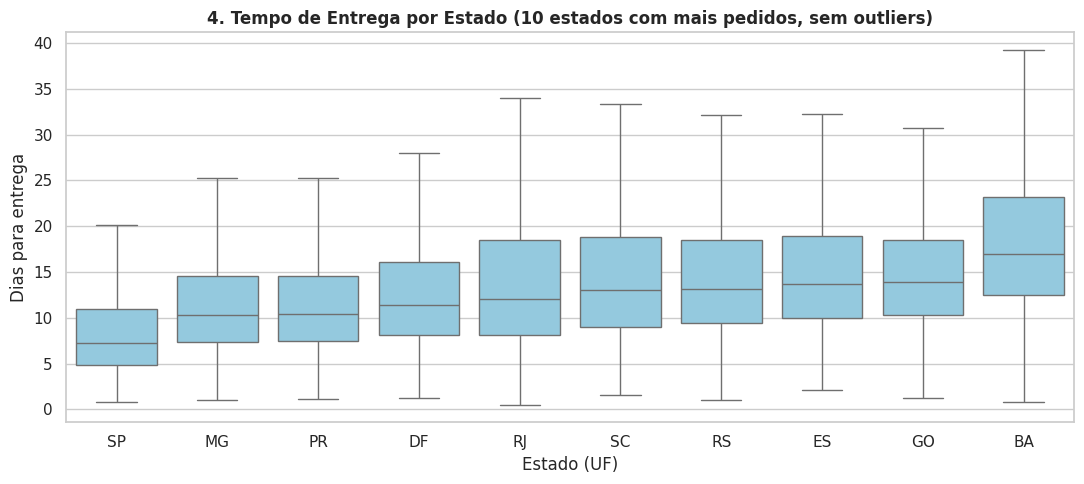

In [ ]:
top10_ufs = df_entregues['customer_state'].value_counts().head(10).index
base_uf = df_entregues[df_entregues['customer_state'].isin(top10_ufs)]

tabela_uf = (
    base_uf.groupby('customer_state')['tempo_entrega_dias']
    .agg(pedidos='count', media='mean', mediana='median', desvio_padrao='std')
    .round(1).sort_values('mediana')
)
display(tabela_uf)

plt.figure(figsize=(11, 5))
sns.boxplot(data=base_uf, x='customer_state', y='tempo_entrega_dias',
            order=tabela_uf.index, color='skyblue', showfliers=False)
plt.title('4. Tempo de Entrega por Estado (10 estados com mais pedidos, sem outliers)', fontsize=12, fontweight='bold')
plt.xlabel('Estado (UF)')
plt.ylabel('Dias para entrega')
plt.tight_layout()
plt.show()

**Minha interpretação:** A análise regional, considerando os 10 estados com maior número de pedidos, mostra diferenças importantes nos tempos de entrega. São Paulo (SP) apresenta a menor mediana, de 7,2 dias, e o menor desvio-padrão, de 6,8 dias, indicando entregas geralmente mais rápidas e menos dispersas. Em contrapartida, a Bahia (BA) registra a maior mediana entre esses estados, com 16,9 dias, além da maior média (19,3 dias) e do maior desvio-padrão (11,7 dias). O Rio de Janeiro (RJ) também apresenta uma dispersão elevada, com desvio-padrão de 11,5 dias. Esses resultados mostram que o tempo de entrega varia bastante entre os estados, mas não permitem identificar, isoladamente, as causas dessas diferenças.

### Análise 4B: % de pedidos atrasados por estado

In [ ]:
atraso_uf = (
    df_entregues.assign(atrasou=df_entregues['dias_atraso'] > 0)
    .groupby('customer_state')
    .agg(pedidos=('order_id', 'count'),
         pct_atrasados=('atrasou', lambda s: s.mean() * 100),
         mediana_entrega=('tempo_entrega_dias', 'median'))
    .query('pedidos >= 300')   # ignora estados com poucos pedidos
    .sort_values('pct_atrasados', ascending=False)
    .round(1)
)
display(atraso_uf)

,pedidos,pct_atrasados,mediana_entrega
customer_state,,,
AL,397,23.9,22.3
MA,717,19.7,19.2
PI,476,16.0,16.3
CE,1279,15.3,18.2
SE,335,15.2,18.0
BA,3256,14.0,16.9
RJ,12350,13.5,12.0
PA,946,12.4,21.1
ES,1995,12.2,13.6


**Minha interpretação:** O percentual de pedidos atrasados varia bastante entre os estados com pelo menos 300 pedidos entregues. Alagoas apresenta a maior taxa, com 23,9%, seguido por Maranhão (19,7%), Piauí (16,0%), Ceará (15,3%) e Sergipe (15,2%). Um resultado relevante é que todos os nove estados do Nordeste incluídos na análise apresentam taxas de atraso superiores a 10%, indicando uma concentração regional desse problema.

Entre os estados com maior volume de pedidos, Bahia registra 14,0% de atrasos e Rio de Janeiro, 13,5%, enquanto São Paulo apresenta 5,9%. A comparação entre Mato Grosso e Rio de Janeiro também chama a atenção: apesar de Mato Grosso ter uma mediana de entrega maior (16,1 dias contra 12,0 dias), sua taxa de atraso é menor (6,8% contra 13,5%). Isso reforça que um tempo de entrega mais longo não significa necessariamente atraso, pois o atraso é calculado em relação à data estimada para cada pedido.

Os estados com menos de 300 pedidos foram excluídos da comparação para evitar interpretações baseadas em amostras pequenas, nas quais as taxas podem variar bastante.

### Análise 5: Evolução mensal de pedidos

Primeiro mês: 800 pedidos | Último mês: 6,512 pedidos | Pico: 7,544 em 11/2017


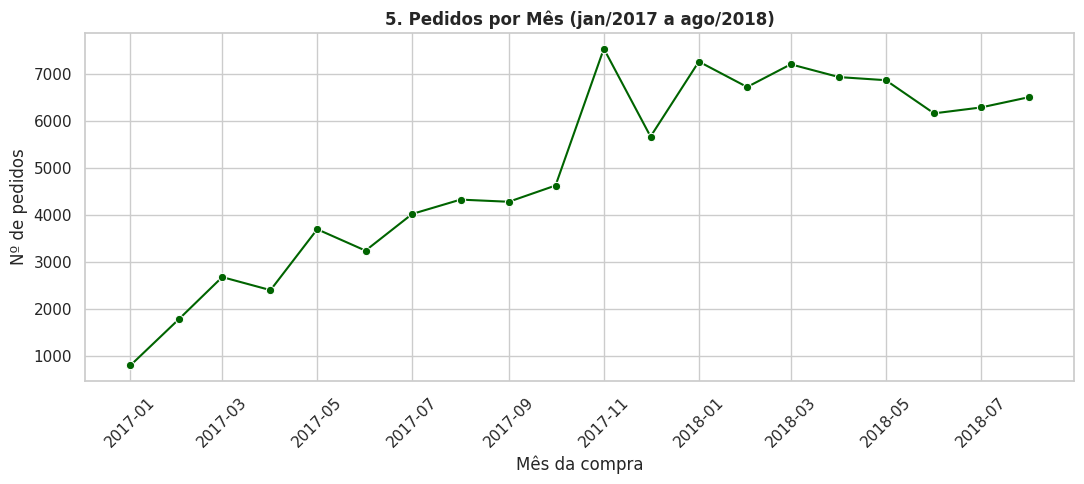

In [ ]:
# Jan/2017 a Ago/2018: os meses fora desse intervalo têm poucos pedidos (início e fim da base)
mensal = (
    df_ped[(df_ped['ano_mes'] >= '2017-01-01') & (df_ped['ano_mes'] <= '2018-08-01')]
    .groupby('ano_mes')['order_id'].nunique()
)
print(f"Primeiro mês: {mensal.iloc[0]:,} pedidos | Último mês: {mensal.iloc[-1]:,} pedidos | Pico: {mensal.max():,} em {mensal.idxmax():%m/%Y}")

plt.figure(figsize=(11, 5))
sns.lineplot(x=mensal.index, y=mensal.values, marker='o', color='darkgreen')
plt.title('5. Pedidos por Mês (jan/2017 a ago/2018)', fontsize=12, fontweight='bold')
plt.xlabel('Mês da compra')
plt.ylabel('Nº de pedidos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Minha interpretação** A evolução temporal demonstra um forte crescimento da plataforma Olist, que saiu de 800 pedidos em janeiro de 2017 para 6.512 em agosto de 2018 (último mês da série). O ponto máximo ocorre em novembro de 2017, com 7.544 pedidos, o que coincide com a Black Friday. Em dezembro o volume cai e, ao longo de 2018, os pedidos se estabilizam em um patamar elevado, entre aproximadamente 6.000 e 7.300 por mês, conforme o gráfico.

### Análise 6: Atraso × nota de avaliação

,pedidos,nota_media,pct_nota_baixa(1-2)
faixa_atraso,,,
No prazo,88163,4.29,0.09
Atraso até 3 dias,2636,3.77,0.19
Atraso de 3 a 7 dias,1773,2.32,0.61
Atraso > 7 dias,3252,1.73,0.78


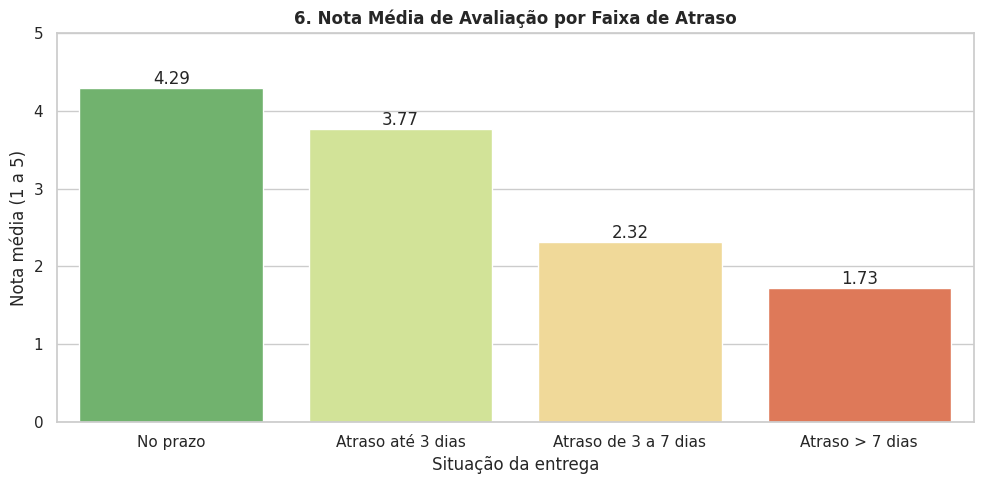

In [ ]:
df_nota = df_entregues.dropna(subset=['review_score', 'dias_atraso'])

resumo_nota = (
    df_nota.groupby('faixa_atraso', observed=True)['review_score']
    .agg(pedidos='count', nota_media='mean')
)
resumo_nota['pct_nota_baixa(1-2)'] = df_nota.groupby('faixa_atraso', observed=True)['review_score'].apply(lambda s: (s <= 2).mean())
display(resumo_nota.round(2))

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=resumo_nota.index.astype(str), y=resumo_nota['nota_media'].values,
                 hue=resumo_nota.index.astype(str), palette='RdYlGn_r', legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')
plt.title('6. Nota Média de Avaliação por Faixa de Atraso', fontsize=12, fontweight='bold')
plt.xlabel('Situação da entrega')
plt.ylabel('Nota média (1 a 5)')
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

**Minha interpretação** O atraso está fortemente associado à queda da satisfação do cliente. Enquanto pedidos entregues no prazo têm nota média alta de 4,29 (com apenas 9% de avaliações negativas), um atraso de até 3 dias já corresponde a uma nota média de 3,77 e dobra a taxa de insatisfação (19%). Quando o atraso ultrapassa 3 dias, a avaliação sofre uma queda brusca: 2,32 para atrasos de 3 a 7 dias (61% de notas 1 ou 2) e 1,73 para atrasos superiores a 7 dias, onde 78% dos clientes atribuem notas 1 ou 2. O cumprimento do prazo estimado mostra-se, portanto, um fator central para a satisfação do consumidor.

### Análise 7: Top 10 estados por número de pedidos

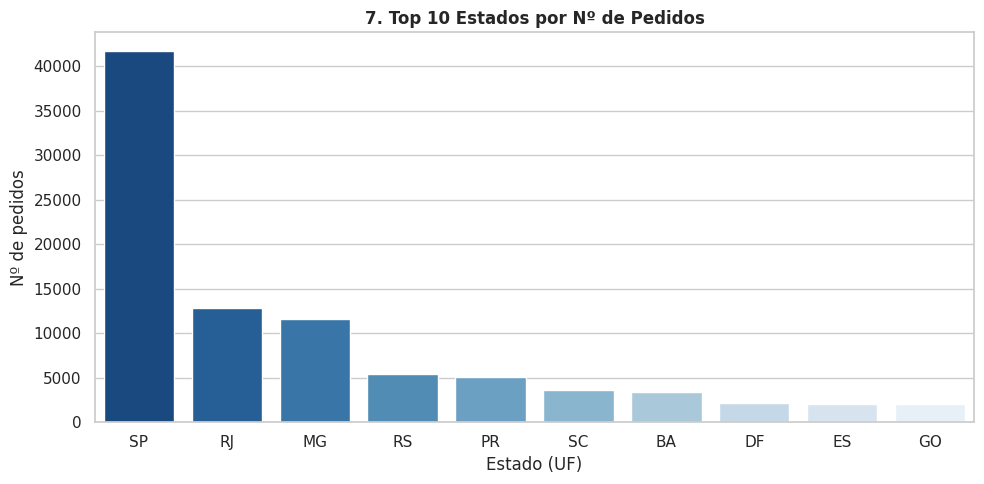

Os 3 maiores estados concentram 66.6% dos pedidos.


In [ ]:
top_states = df_ped['customer_state'].value_counts().head(10).reset_index()
top_states.columns = ['customer_state', 'count']

plt.figure(figsize=(10, 5))
sns.barplot(data=top_states, x='customer_state', y='count', hue='customer_state',
            palette='Blues_r', legend=False)
plt.title('7. Top 10 Estados por Nº de Pedidos', fontsize=12, fontweight='bold')
plt.xlabel('Estado (UF)')
plt.ylabel('Nº de pedidos')
plt.tight_layout()
plt.show()

print(f"Os 3 maiores estados concentram {top_states['count'].head(3).sum() / len(df_ped):.1%} dos pedidos.")

**Minha interpretação:** A distribuição geográfica dos pedidos evidencia uma elevada centralização do consumo no Sudeste do Brasil, onde apenas três estados (São Paulo, Rio de Janeiro e Minas Gerais) concentram 66,6% dos pedidos. São Paulo destaca-se isoladamente como o principal mercado consumidor, sendo responsável por aproximadamente 42% das transações. Esta concentração reforça a importância estratégica de manter centros de distribuição e vendedores próximos dessa região para otimizar prazos e custos de envio, ao mesmo tempo que assinala oportunidades de expansão comercial nas regiões Sul, Nordeste e Centro-Oeste.

### Análise 8: Categorias mais vendidas × categorias que mais faturam

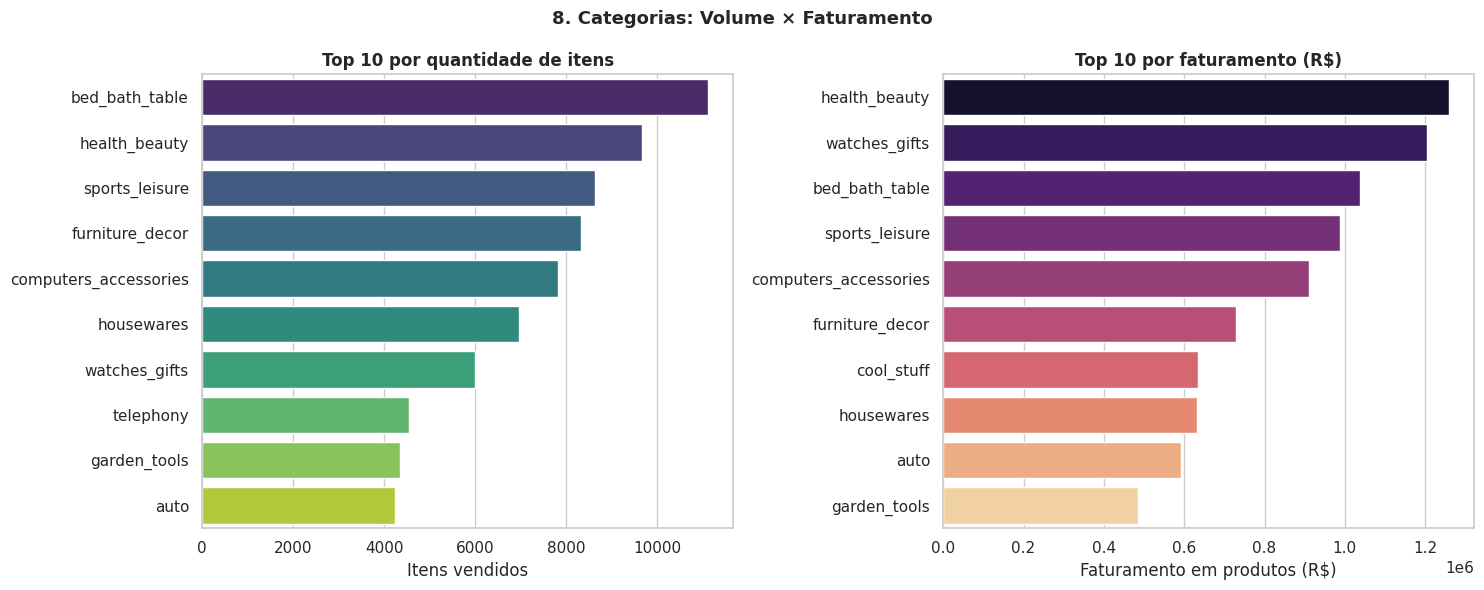

Estão no top 10 de faturamento mas não no de quantidade: ['cool_stuff']


In [ ]:
itens_vendidos = df_merged.dropna(subset=['price'])

top_qtd = itens_vendidos['categoria'].value_counts().head(10)
top_fat = itens_vendidos.groupby('categoria')['price'].sum().nlargest(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(x=top_qtd.values, y=top_qtd.index, hue=top_qtd.index, palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Top 10 por quantidade de itens', fontweight='bold')
axes[0].set_xlabel('Itens vendidos'); axes[0].set_ylabel('')

sns.barplot(x=top_fat.values, y=top_fat.index, hue=top_fat.index, palette='magma', legend=False, ax=axes[1])
axes[1].set_title('Top 10 por faturamento (R$)', fontweight='bold')
axes[1].set_xlabel('Faturamento em produtos (R$)'); axes[1].set_ylabel('')

fig.suptitle('8. Categorias: Volume × Faturamento', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Estão no top 10 de faturamento mas não no de quantidade:", sorted(set(top_fat.index) - set(top_qtd.index)))

In [ ]:
tabela_cat = (
    itens_vendidos.groupby('categoria')['price']
    .agg(itens='count', faturamento='sum', ticket_medio='mean')
    .round(2).sort_values('faturamento', ascending=False).head(10)
)
display(tabela_cat)

,itens,faturamento,ticket_medio
categoria,,,
health_beauty,9670,1258681.34,130.16
watches_gifts,5991,1205005.68,201.14
bed_bath_table,11115,1036988.68,93.30
sports_leisure,8641,988048.97,114.34
computers_accessories,7827,911954.32,116.51
furniture_decor,8334,729762.49,87.56
cool_stuff,3796,635290.85,167.36
housewares,6964,632248.66,90.79
auto,4235,592720.11,139.96


**Minha interpretação:** A comparação entre volume de vendas e faturamento mostra que as categorias com maior quantidade de itens vendidos nem sempre são as de maior receita. Enquanto bed_bath_table lidera em volume (11.115 itens) com um ticket médio mais acessível de R$ 93,30, a categoria health_beauty gera a maior receita acumulada (R$ 1,26 milhão) com 9.670 itens. Além disso, categorias de maior valor unitário, como watches_gifts (ticket médio de R$ 201,14) e cool_stuff (ticket médio de R$ 167,36), figuram entre as que mais faturam mesmo com volumes menores; cool_stuff aparece no top 10 de faturamento sem estar entre as 10 mais vendidas em quantidade.

### Análise 9: Peso × frete

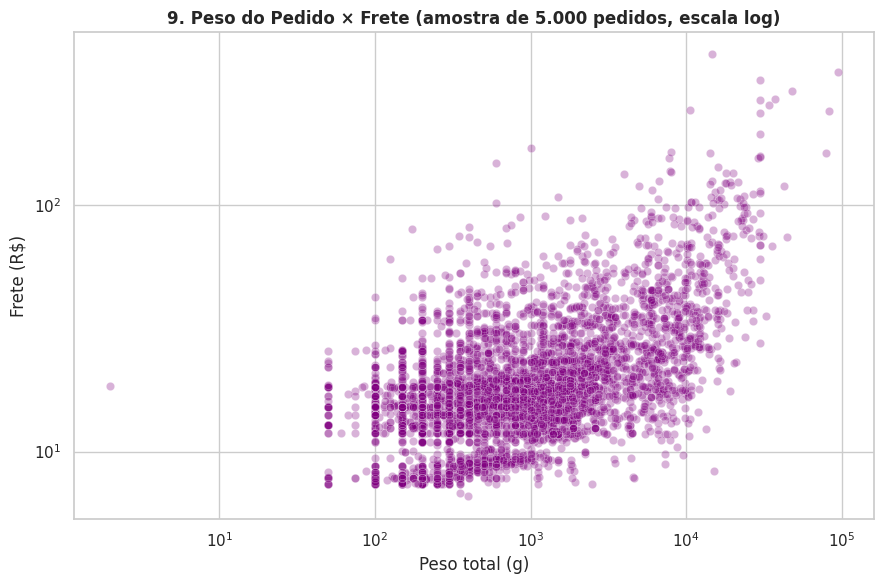

In [ ]:
base_disp = df_entregues.dropna(subset=['peso_total_g', 'frete'])
base_disp = base_disp[base_disp['frete'] > 0]
amostra = base_disp.sample(min(5000, len(base_disp)), random_state=42)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=amostra, x='peso_total_g', y='frete', alpha=0.3, color='purple')
plt.xscale('log'); plt.yscale('log')
plt.title('9. Peso do Pedido × Frete (amostra de 5.000 pedidos, escala log)', fontsize=12, fontweight='bold')
plt.xlabel('Peso total (g)')
plt.ylabel('Frete (R$)')
plt.tight_layout()
plt.show()

**Minha interpretação:** A relação entre o peso do pedido e o valor do frete apresenta uma tendência positiva em escala logarítmica, com correlação de Spearman de 0,49 (Análise 3). Encomendas mais pesadas tendem a apresentar fretes progressivamente maiores. No entanto, a visível dispersão vertical nos mesmos patamares de peso indica que o peso físico não é a única variável: fatores não medidos neste projeto, como a distância entre vendedor e comprador e a modalidade de entrega, podem explicar parte dessa dispersão.

## 8. Exportação das tabelas para o Google Data Studio

In [ ]:
os.makedirs('saida_datastudio', exist_ok=True)

pedidos_out = df_ped[[
    'order_id', 'order_status', 'ano_mes', 'customer_state', 'uf_br',
    'tempo_entrega_dias', 'dias_atraso', 'faixa_atraso', 'situacao_entrega',
    'valor_produtos', 'frete', 'peso_total_g', 'n_itens', 'review_score',
]].copy()
pedidos_out['data_mes'] = pedidos_out.pop('ano_mes').dt.strftime('%Y-%m-%d')
pedidos_out['faixa_atraso'] = pedidos_out['faixa_atraso'].astype(object).fillna('Sem entrega registrada')
pedidos_out = pedidos_out.round({'tempo_entrega_dias': 1, 'dias_atraso': 1})

itens_out = df_merged.dropna(subset=['price'])[[
    'order_id', 'order_item_id', 'ano_mes', 'customer_state', 'uf_br',
    'categoria', 'price', 'freight_value', 'valor_total_item',
]].copy()
itens_out['data_mes'] = itens_out.pop('ano_mes').dt.strftime('%Y-%m-%d')

pedidos_out.to_csv('saida_datastudio/pedidos_datastudio.csv', index=False)
itens_out.to_csv('saida_datastudio/itens_datastudio.csv', index=False)

for nome in ['pedidos_datastudio.csv', 'itens_datastudio.csv']:
    tam = os.path.getsize(f'saida_datastudio/{nome}') / 1024**2
    print(f"{nome}: {tam:.1f} MB")

try:
    from google.colab import files
    files.download('saida_datastudio/pedidos_datastudio.csv')
    files.download('saida_datastudio/itens_datastudio.csv')
except ImportError:
    print("Fora do Colab: arquivos salvos na pasta saida_datastudio/")

pedidos_datastudio.csv: 11.0 MB
itens_datastudio.csv: 9.8 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusões

### Resposta à Pergunta Norteadora

**"O que explica os atrasos nas entregas e como eles afetam a satisfação do cliente?"**

Os resultados mostram que 8,1% dos pedidos entregues analisados chegaram após a data estimada. Embora os atrasos representem uma parcela minoritária das entregas, eles estão fortemente associados à redução da satisfação dos clientes. A nota média cai de 4,29 nos pedidos entregues no prazo para 1,73 nos pedidos com atrasos superiores a sete dias.

Em relação aos fatores associados aos atrasos, a análise regional identificou diferenças expressivas entre os estados. Alagoas apresentou a maior taxa de atraso (23,9%), enquanto Paraná registrou a menor (5,0%) entre os estados com pelo menos 300 pedidos entregues. Todos os nove estados do Nordeste incluídos nesse recorte apresentaram taxas superiores a 10%.

A comparação entre Mato Grosso e Rio de Janeiro também demonstra que o tempo de entrega, isoladamente, não determina a ocorrência de atraso: Mato Grosso apresentou mediana de entrega de 16,1 dias e 6,8% de pedidos atrasados, enquanto o Rio de Janeiro registrou mediana de 12,0 dias e 13,5% de atrasos.

Portanto, os dados permitem identificar diferenças regionais e uma forte associação entre atrasos e avaliações negativas, mas não comprovam as causas operacionais do problema. Para isso, seriam necessárias informações adicionais sobre distância, localização dos vendedores, transportadoras e processos logísticos.

---

### Síntese dos Resultados

**1. Entrega**
- **Tempo típico:** mediana de 10,2 dias e média de 12,6 dias.
- **Atrasos:** 8,1% dos pedidos entregues analisados chegaram após a data estimada.
- A distribuição do tempo de entrega apresenta assimetria positiva, indicando a existência de pedidos com prazos muito superiores ao padrão.

**2. Diferenças regionais**
- **Menor mediana de entrega:** São Paulo (SP), com 7,2 dias.
- **Maior mediana entre os 10 estados com mais pedidos:** Bahia (BA), com 16,9 dias.
- **Maior percentual de atrasos:** Alagoas (AL), com 23,9%.
- **Menor percentual de atrasos:** Paraná (PR), com 5,0%, entre os estados com pelo menos 300 pedidos.
- Todos os nove estados nordestinos incluídos na comparação apresentaram mais de 10% de pedidos atrasados.

**3. Satisfação dos clientes**

A relação entre atraso e avaliação apresenta uma diferença expressiva:
- **No prazo:** nota média de 4,29, com 9% de avaliações negativas (notas 1 ou 2).
- **Atraso de até 3 dias:** nota média de 3,77, com 19% de avaliações negativas.
- **Atraso de 3 a 7 dias:** nota média de 2,32, com 61% de avaliações negativas.
- **Atraso superior a 7 dias:** nota média de 1,73, com 78% de avaliações negativas.

Os resultados indicam que atrasos mais longos estão associados a avaliações progressivamente piores.

**4. Aspectos de negócio**
- **Crescimento temporal:** o volume mensal passou de 800 pedidos em janeiro de 2017 para 6.512 em agosto de 2018, atingindo o pico de 7.544 pedidos em novembro de 2017.
- **Concentração geográfica:** São Paulo, Rio de Janeiro e Minas Gerais concentram 66,6% dos pedidos da plataforma.
- **Categorias:** Cama, Mesa e Banho lidera em quantidade, com 11.115 itens vendidos. Beleza e Saúde apresenta o maior faturamento de produtos, com aproximadamente R$ 1,26 milhão. Relógios e Presentes possui o maior ticket médio entre as categorias analisadas, de R$ 201,14.
- O faturamento por categoria considera o preço dos produtos, sem incluir o valor do frete.

---

### Limitações da Análise

Os resultados devem ser interpretados considerando algumas limitações da base:
- Estados com menos de 300 pedidos entregues foram excluídos da comparação regional para reduzir a influência de amostras pequenas.
- A análise identifica associações entre variáveis, mas não permite estabelecer relações de causa e efeito.
- Não foram utilizadas informações detalhadas sobre distância, vendedores e transportadoras, o que limita a identificação das causas dos atrasos.
- A base apresenta alguns registros com inconsistências nas datas de entrega, que foram identificados durante o tratamento dos dados.

---

### Recomendações

Com base nos resultados, algumas ações podem contribuir para melhorar a operação:
- Investigar os estados com maiores taxas de atraso, especialmente os nove estados nordestinos identificados na análise.
- Avaliar os processos logísticos nas regiões com maior incidência de entregas fora do prazo.
- Acompanhar os atrasos mais longos, pois apresentam associação mais forte com avaliações negativas.
- Monitorar indicadores de entrega e satisfação por estado, permitindo identificar mudanças no desempenho ao longo do tempo.

O acompanhamento contínuo desses indicadores pode ajudar a direcionar melhorias logísticas e reduzir os impactos dos atrasos na experiência dos clientes.